# Airline Quality Analysis

In this notebook, logistic regression analysis is performed on a airline quality ratings dataset to examine how selected airline services contribute to better passenger satisfaction. Model performance is evaluated using training, validation, and test data, followed by repeated and nested cross-validation.

Link to the dataset: [Kaggle Airline Dataset Link](https://www.kaggle.com/datasets/mikhail1681/airline-quality-ratings)

First, the requred libraries are imported and the dataset is loaded into a Pandas DataFrame.

In [216]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv("Airline Quality Ratings.csv")

Next, the dataset structure and contents are examined, relevant variables are selected, missing (NaN) values are cleaned or filtered if requred, and the data is split into training, validation, and test sets.

In [217]:
# Explore dataset 
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  129880 non-null

In [218]:
# Remove irrelavant variables
df = df.drop(columns=[
    'ID', 
    'Gender', 
    'Age', 
    'Customer Type', 
    'Flight Distance', 
    'Departure Delay', 
    'Arrival Delay', 
    'Ease of Online Booking', 
    'Check-in Service', 
    'Online Boarding', 
    'Gate Location', 
    'Type of Travel',
    'Class',
    'Baggage Handling'
])

# Remove rows containing NaN values
df = df.dropna(how = 'any')

# Explore the remaining data
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 10 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   Departure and Arrival Time Convenience  129880 non-null  int64
 1   On-board Service                        129880 non-null  int64
 2   Seat Comfort                            129880 non-null  int64
 3   Leg Room Service                        129880 non-null  int64
 4   Cleanliness                             129880 non-null  int64
 5   Food and Drink                          129880 non-null  int64
 6   In-flight Service                       129880 non-null  int64
 7   In-flight Wifi Service                  129880 non-null  int64
 8   In-flight Entertainment                 129880 non-null  int64
 9   Satisfaction                            129880 non-null  str  
dtypes: int64(9), str(1)
memory usage: 9.9 MB
None


In [219]:
# Explore each variable individually
print(df['Satisfaction'].value_counts())
print()

services = df[[
    'Departure and Arrival Time Convenience',
    'On-board Service',
    'Seat Comfort',
    'Leg Room Service',
    'Cleanliness',
    'Food and Drink',
    'In-flight Service',
    'In-flight Wifi Service',
    'In-flight Entertainment']]
print(services.describe())

Satisfaction
Neutral or Dissatisfied    73452
Satisfied                  56428
Name: count, dtype: int64

       Departure and Arrival Time Convenience  On-board Service  \
count                           129880.000000     129880.000000   
mean                                 3.057599          3.383023   
std                                  1.526741          1.287099   
min                                  0.000000          0.000000   
25%                                  2.000000          2.000000   
50%                                  3.000000          4.000000   
75%                                  4.000000          4.000000   
max                                  5.000000          5.000000   

        Seat Comfort  Leg Room Service    Cleanliness  Food and Drink  \
count  129880.000000     129880.000000  129880.000000   129880.000000   
mean        3.441361          3.350878       3.286326        3.204774   
std         1.319289          1.316252       1.313682        1.329933  

In [220]:
# Convert the dependent variable to binary
df['Satisfaction'] = df['Satisfaction'].eq('Satisfied').astype(int)

print(df['Satisfaction'].value_counts())

Satisfaction
0    73452
1    56428
Name: count, dtype: int64


The dependent variable used for the prediction analysis is 'Satisfaction'. It contains 2 categories: 'Neutral or Dissatisfied' and 'Satisfied', which were converted into a binary format, 0 and 1, respectively, to enable logistic regression analysis. Their distribution is uneven, with 73,452 passengers classified as 'Neutral or Dissatisfied'(0) and 56,428 passengers classified as 'Satisfied'(1). This imbalance should be considered when evaluating the performance of the prediction model.

Nine independent variables were selected to examine association with airline quality satisfaction: 'Departure and Arrival Time Convenience', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', and 'In-flight Entertainment'. Exploring the dataset showed that all of these variables were collected through a passenger questionnaire, with scores going from 0 to 5. The ratings are self‑reported, introducing bias and uncertainty, since the fairness of the estimation cannot be easily confirmed.

To provide an overview of passenger satisfaction across the selected variables, the overall and individual average satisfaction rates of all passengers who were both satisfied and gave each service a score above the selected threshold are estimated. The thresholds are greater than 2 for time convenience and greater than 3 for the other services.

In [221]:
# Overall satisfaction percentage
Average_satisfaction_rate = (
    len(df[df['Satisfaction'] == 1]) / len(df['Satisfaction']) * 100
)

print(f"Average Satisfaction Rate: {Average_satisfaction_rate:.2f}%")

# Time Convenience
ASR_Deptime = (
    len(df[(df['Departure and Arrival Time Convenience'] > 2) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"Departure and Arrival Time Convenience SR: {ASR_Deptime:.2f}%")

# On-board Service
ASR_OnboardService = (
    len(df[(df['On-board Service'] > 3) &
               (df['Satisfaction'] == 1)])
        / len(df['Satisfaction']) * 100
)

print(f"On-board Service SR: {ASR_OnboardService:.2f}%")

# Seat Comfort
ASR_Seat = (
    len(df[(df['Seat Comfort'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"Seat Comfort SR: {ASR_Seat:.2f}%")

# Leg Room Service
ASR_LegRoom = (
    len(df[(df['Leg Room Service'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"Leg Room Service SR: {ASR_LegRoom:.2f}%")

# Cleaniness
ASR_Cleanliness = (
    len(df[(df['Cleanliness'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"Cleanliness SR: {ASR_Cleanliness:.2f}%")

# Food and Drink
ASR_FoodDrink = (
    len(df[(df['Food and Drink'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"Food and Drink SR: {ASR_FoodDrink:.2f}%")

# In-flight Service
ASR_InflightService = (
    len(df[(df['In-flight Service'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"In-flight Service SR: {ASR_InflightService:.2f}%")

# In-flight Wifi Service
ASR_Wifi = (
    len(df[(df['In-flight Wifi Service'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"In-flight Wifi Service SR: {ASR_Wifi:.2f}%")

# In-flight Entertainment
ASR_Entertainment = (
    len(df[(df['In-flight Entertainment'] > 3) &
           (df['Satisfaction'] == 1)])
    / len(df['Satisfaction']) * 100
)

print(f"In-flight Entertainment SR: {ASR_Entertainment:.2f}%")

Average Satisfaction Rate: 43.45%
Departure and Arrival Time Convenience SR: 26.27%
On-board Service SR: 30.61%
Seat Comfort SR: 33.78%
Leg Room Service SR: 30.73%
Cleanliness SR: 27.40%
Food and Drink SR: 24.23%
In-flight Service SR: 33.46%
In-flight Wifi Service SR: 22.40%
In-flight Entertainment SR: 33.11%


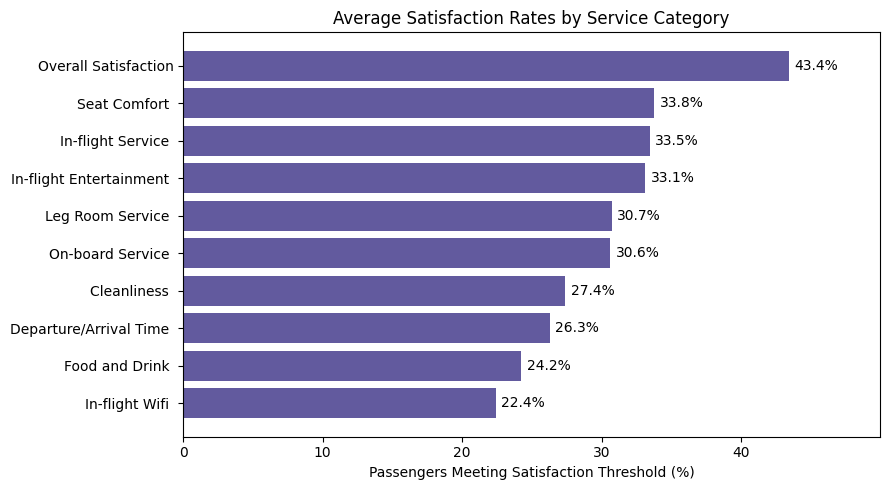

In [222]:
rates = {
    "Overall Satisfaction": Average_satisfaction_rate,
    "Departure/Arrival Time ": ASR_Deptime,
    "On-board Service ":ASR_OnboardService,
    "Seat Comfort ": ASR_Seat,
    "Leg Room Service ": ASR_LegRoom,
    "Cleanliness ": ASR_Cleanliness,
    "Food and Drink ": ASR_FoodDrink,
    "In-flight Service ": ASR_InflightService,
    "In-flight Wifi ": ASR_Wifi,
    "In-flight Entertainment ": ASR_Entertainment,
}

# Sort from lowest to highest for easier reading
rates_series = pd.Series(rates).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(rates_series.index, rates_series.values, color="#625A9E")

ax.set_xlabel("Passengers Meeting Satisfaction Threshold (%)")
ax.set_title("Average Satisfaction Rates by Service Category")
ax.set_xlim(0, max(rates_series.values) * 1.15)
ax.bar_label(bars, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

The overall passenger satisfaction percentage was 43.45%. Out of the services, Seat Comfort (33.78%), In-flight Service (33.46%), and In-flight Entertainment (33.11%) had the highest satisfaction rates, while In-flight WiFi Service (22.40%) and Food and Drink (24.23%) had the lowest. Departure and Arrival Time Convenience (26.27%), Cleanliness (27.40%), On-board Service (30.61%), and Leg Room Service (30.73%) showed moderate satisfaction rates. 

These ratings depend on two conditions: 
1. the pasinger was satisfied;
2. the passenger gave the service a rating above the specified threshold.

The results suggest that passengers who were satisfied more often gave a rating above the requred treshold for comfort and service-related aspects of the flight, rather than WiFi and catering.

Next, logustic regression analysis is performed to examine how the selected service ratings predict passenger satisfaction. The model's prediction performance is evaluated using a training, validation, and test workflow. This prevents data leakage and keeps model selection honest.

In [223]:
services = services.to_numpy()
y = df['Satisfaction'].to_numpy()

# 80% Train+Validation, 20% Test
services_train_val, services_test, y_train_val, y_test = train_test_split(
    services,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split the 80% into 60% Train and 20% Validation
services_train, services_val, y_train, y_val = train_test_split(
    services_train_val,
    y_train_val,
    test_size=0.25, 
    random_state=42,
    stratify=y_train_val
)

print(f"Train: {len(services_train)}")
print(f"Validation: {len(services_val)}")
print(f"Test: {len(services_test)}")

print(f"Train satisfaction rate: {y_train.mean():.3f}")
print(f"Validation satisfaction rate: {y_val.mean():.3f}")
print(f"Test satisfaction rate: {y_test.mean():.3f}")

Train: 77928
Validation: 25976
Test: 25976
Train satisfaction rate: 0.434
Validation satisfaction rate: 0.434
Test satisfaction rate: 0.434


In [224]:
services_train_df = pd.DataFrame(
    services_train,
    columns=[
        'Departure and Arrival Time Convenience',
        'On-board Service',
        'Seat Comfort',
        'Leg Room Service',
        'Cleanliness',
        'Food and Drink',
        'In-flight Service',
        'In-flight Wifi Service',
        'In-flight Entertainment'
    ]
)

time_convinience = services_train_df[['Departure and Arrival Time Convenience']]
model_t = LogisticRegression(C=1.0, max_iter=1000)
model_t.fit(time_convinience, y_train)
print("Time Convenience Model Score:", model_t.score(time_convinience, y_train))

ob_service = services_train_df[['On-board Service']]
model_ob_service = LogisticRegression(C=1.0, max_iter=1000)
model_ob_service.fit(ob_service, y_train)
print("On-board Service Model Score:", model_ob_service.score(ob_service, y_train))

seats = services_train_df[['Seat Comfort']]
model_seats = LogisticRegression(C=1.0, max_iter=1000)
model_seats.fit(seats, y_train)
print("Seats Model Score:", model_seats.score(seats, y_train))

lroom = services_train_df[['Leg Room Service']]
model_lroom = LogisticRegression(C=1.0, max_iter=1000)
model_lroom.fit(lroom, y_train)
print("Leg Room Service Model Score:", model_lroom.score(lroom, y_train))

cleanliness = services_train_df[['Cleanliness']]
model_clean = LogisticRegression(C=1.0, max_iter=1000)
model_clean.fit(cleanliness, y_train)
print("Cleanliness Model Score:", model_clean.score(cleanliness, y_train))

fnd = services_train_df[['Food and Drink']]
model_fnd = LogisticRegression(C=1.0, max_iter=1000)
model_fnd.fit(fnd, y_train)
print("Food and Drink Model Score:", model_fnd.score(fnd, y_train))

if_service = services_train_df[['In-flight Service']]
model_if_service = LogisticRegression(C=1.0, max_iter=1000)
model_if_service.fit(if_service, y_train)
print("In-flight Service Model Score:", model_if_service.score(if_service, y_train))

wifi = services_train_df[['In-flight Wifi Service']]
model_wifi = LogisticRegression(C=1.0, max_iter=1000)
model_wifi.fit(wifi, y_train)
print("In-flight Wifi Service Model Score:", model_wifi.score(wifi, y_train))

entertainment = services_train_df[['In-flight Entertainment']]
model_entertainment = LogisticRegression(C=1.0, max_iter=1000)
model_entertainment.fit(entertainment, y_train)
print("In-flight Entertainment Model Score:", model_entertainment.score(entertainment, y_train))

Time Convenience Model Score: 0.5655348526845293
On-board Service Model Score: 0.6514731547069089
Seats Model Score: 0.6792680422954522
Leg Room Service Model Score: 0.6666153372343702
Cleanliness Model Score: 0.6322502823118776
Food and Drink Model Score: 0.5857073195770455
In-flight Service Model Score: 0.6234216199568833
In-flight Wifi Service Model Score: 0.7122087054717174
In-flight Entertainment Model Score: 0.7012113746021968


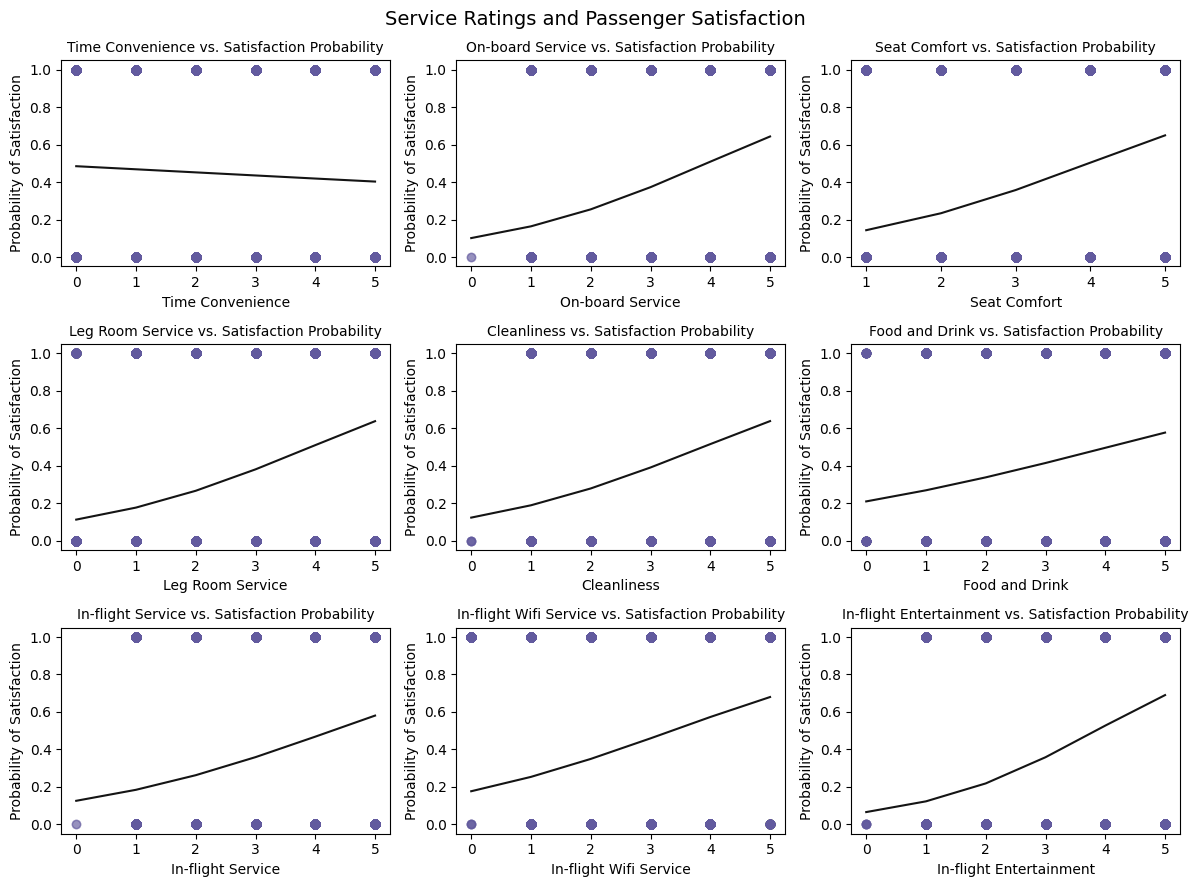

In [225]:
fig, ax = plt.subplots(3, 3, figsize=(12, 9))

plt.suptitle('Service Ratings and Passenger Satisfaction', fontsize=14)

# Time Convenience
prob = model_t.predict_proba(time_convinience)
order = np.argsort(time_convinience['Departure and Arrival Time Convenience'])

ax[0,0].scatter(time_convinience['Departure and Arrival Time Convenience'], y_train, c='#625A9E', alpha=0.3)
ax[0,0].plot(time_convinience['Departure and Arrival Time Convenience'].iloc[order], prob[:,1][order], c='#141414')

ax[0,0].set_xlabel("Time Convenience")
ax[0,0].set_ylabel("Probability of Satisfaction")
ax[0,0].set_title("Time Convenience vs. Satisfaction Probability", fontsize=10)

# On-board Service
prob = model_ob_service.predict_proba(ob_service)
order = np.argsort(ob_service['On-board Service'])

ax[0,1].scatter(ob_service['On-board Service'], y_train, c='#625A9E', alpha=0.3)
ax[0,1].plot(ob_service['On-board Service'].iloc[order], prob[:,1][order], c='#141414')

ax[0,1].set_xlabel("On-board Service")
ax[0,1].set_ylabel("Probability of Satisfaction")
ax[0,1].set_title("On-board Service vs. Satisfaction Probability", fontsize=10)

# Seat Comfort
prob = model_seats.predict_proba(seats)
order = np.argsort(seats['Seat Comfort'])

ax[0,2].scatter(seats['Seat Comfort'], y_train, c='#625A9E', alpha=0.3)
ax[0,2].plot(seats['Seat Comfort'].iloc[order], prob[:,1][order], c='#141414')

ax[0,2].set_xlabel("Seat Comfort")
ax[0,2].set_ylabel("Probability of Satisfaction")
ax[0,2].set_title("Seat Comfort vs. Satisfaction Probability", fontsize=10)

# Leg Room Service
prob = model_lroom.predict_proba(lroom)
order = np.argsort(lroom['Leg Room Service'])

ax[1,0].scatter(lroom['Leg Room Service'], y_train, c='#625A9E', alpha=0.3)
ax[1,0].plot(lroom['Leg Room Service'].iloc[order], prob[:,1][order], c='#141414')

ax[1,0].set_xlabel("Leg Room Service")
ax[1,0].set_ylabel("Probability of Satisfaction")
ax[1,0].set_title("Leg Room Service vs. Satisfaction Probability", fontsize=10)

# Cleanliness
prob = model_clean.predict_proba(cleanliness)
order = np.argsort(cleanliness['Cleanliness'])

ax[1,1].scatter(cleanliness['Cleanliness'], y_train, c='#625A9E', alpha=0.3)
ax[1,1].plot(cleanliness['Cleanliness'].iloc[order], prob[:,1][order], c='#141414')

ax[1,1].set_xlabel("Cleanliness")
ax[1,1].set_ylabel("Probability of Satisfaction")
ax[1,1].set_title("Cleanliness vs. Satisfaction Probability", fontsize=10)

# Food and Drink
prob = model_fnd.predict_proba(fnd)
order = np.argsort(fnd['Food and Drink'])

ax[1,2].scatter(fnd['Food and Drink'], y_train, c='#625A9E', alpha=0.3)
ax[1,2].plot(fnd['Food and Drink'].iloc[order], prob[:,1][order], c='#141414')

ax[1,2].set_xlabel("Food and Drink")
ax[1,2].set_ylabel("Probability of Satisfaction")
ax[1,2].set_title("Food and Drink vs. Satisfaction Probability", fontsize=10)

# In-flight Service
prob = model_if_service.predict_proba(if_service)
order = np.argsort(if_service['In-flight Service'])

ax[2,0].scatter(if_service['In-flight Service'], y_train, c='#625A9E', alpha=0.3)
ax[2,0].plot(if_service['In-flight Service'].iloc[order], prob[:,1][order], c='#141414')

ax[2,0].set_xlabel("In-flight Service")
ax[2,0].set_ylabel("Probability of Satisfaction")
ax[2,0].set_title("In-flight Service vs. Satisfaction Probability", fontsize=10)

# In-flight Wifi Service
prob = model_wifi.predict_proba(wifi)
order = np.argsort(wifi['In-flight Wifi Service'])

ax[2,1].scatter(wifi['In-flight Wifi Service'], y_train, c='#625A9E', alpha=0.3)
ax[2,1].plot(wifi['In-flight Wifi Service'].iloc[order], prob[:,1][order], c='#141414')

ax[2,1].set_xlabel("In-flight Wifi Service")
ax[2,1].set_ylabel("Probability of Satisfaction")
ax[2,1].set_title("In-flight Wifi Service vs. Satisfaction Probability", fontsize=10)

# In-flight Entertainment
prob = model_entertainment.predict_proba(entertainment)
order = np.argsort(entertainment['In-flight Entertainment'])

ax[2,2].scatter(entertainment['In-flight Entertainment'], y_train, c='#625A9E', alpha=0.3)
ax[2,2].plot(entertainment['In-flight Entertainment'].iloc[order], prob[:,1][order], c='#141414')

ax[2,2].set_xlabel("In-flight Entertainment")
ax[2,2].set_ylabel("Probability of Satisfaction")
ax[2,2].set_title("In-flight Entertainment vs. Satisfaction Probability", fontsize=10)

plt.tight_layout()
plt.show()

Training Score: 0.7675290011292475
Validation Score: 0.7702879581151832
[[11856  2835]
 [ 3132  8153]]


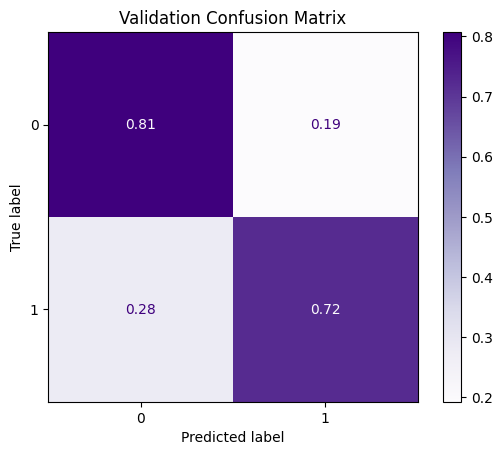

In [226]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model_all = LogisticRegression(max_iter=1000, C=np.inf)

model_all.fit(services_train, y_train)

print("Training Score:", model_all.score(services_train, y_train))
print("Validation Score:", model_all.score(services_val, y_val))

Yhat_val = model_all.predict(services_val)

confmat_val = confusion_matrix(y_val, Yhat_val)
print(confmat_val)

ConfusionMatrixDisplay.from_estimator(
    model_all,
    services_val,
    y_val,
    normalize='true',
    cmap='Purples'
)

plt.title("Validation Confusion Matrix")
plt.show()

Final Test Score: 0.7709424083769634
[[11853  2837]
 [ 3113  8173]]


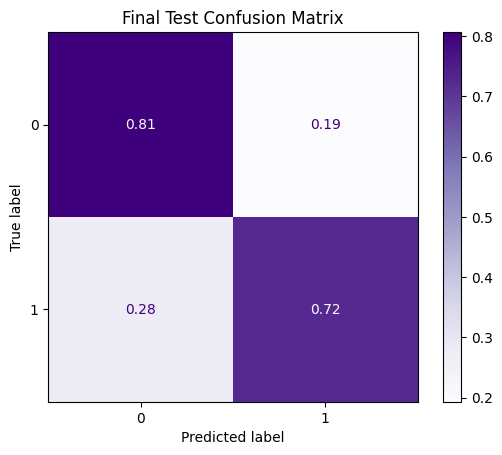

In [227]:
final_model = LogisticRegression(max_iter=1000, C=np.inf)

final_model.fit(services_train_val, y_train_val)

print("Final Test Score:",
      final_model.score(services_test, y_test))

Yhat_test = final_model.predict(services_test)

confmat_test = confusion_matrix(y_test, Yhat_test)
print(confmat_test)

ConfusionMatrixDisplay.from_estimator(
    final_model,
    services_test,
    y_test,
    normalize='true',
    cmap='Purples'
)

plt.title("Final Test Confusion Matrix")
plt.show()

0.7689460600994324
0.7686710809978441


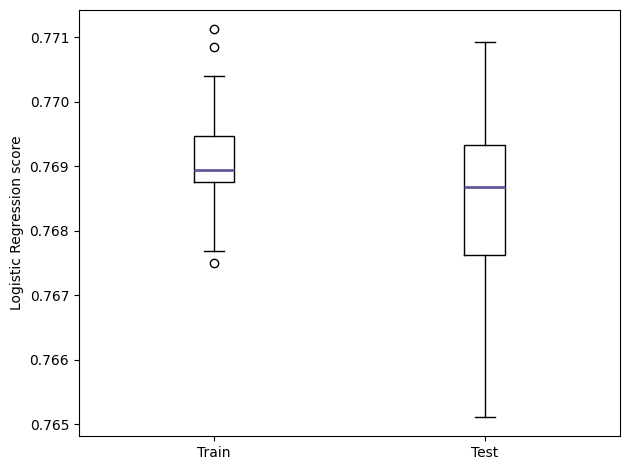

In [228]:
n_trials = 50
score_tv = list()
score_te = list()
splits = ShuffleSplit(n_splits=n_trials, train_size=0.7, random_state=42)
for train, test in splits.split(services):
    services_tv,y_tv = services[train], y[train]
    services_te,y_te = services[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(services_tv, y_tv)
    score_tv.append(ovr.score(services_tv,y_tv))
    score_te.append(ovr.score(services_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='#625A9E', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train','Test'])
plt.tight_layout()

print(np.median(score_tv))
print(np.median(score_te))

plt.show()

0.7690175546658454
0.7681577866748793


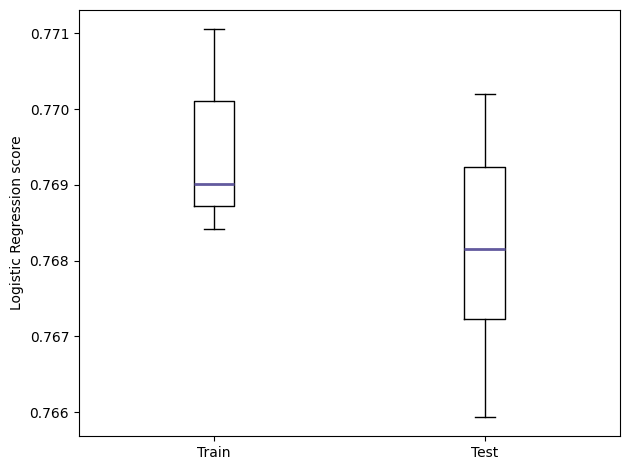

In [229]:
# Stratification splits
n_trials = 10
score_tv = list()
score_te = list()
split = StratifiedShuffleSplit(n_splits=n_trials, train_size=0.7,random_state=42)
for train, test in split.split(services, y):
    services_tv,y_tv = services[train], y[train]
    services_te,y_te = services[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(services_tv, y_tv)
    score_tv.append(ovr.score(services_tv,y_tv))
    score_te.append(ovr.score(services_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='#625A9E', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train','Test'])
plt.tight_layout()

print(np.median(score_tv))
print(np.median(score_te))

plt.show()

In [230]:

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
models = [ovr, ovo]

param_grid = {'estimator__C': np.logspace(-4, 3, num=8)}

n_outer_splits = 5
n_repeats = 5
n_inner_splits = 8

test_scores = np.zeros((n_outer_splits * n_repeats, len(models)))
model_choice = np.zeros(n_outer_splits * n_repeats)
param_choice = np.zeros(n_outer_splits * n_repeats)

outercv = RepeatedStratifiedKFold(
    n_splits=n_outer_splits,
    n_repeats=n_repeats,
    random_state=42
)

innercv = StratifiedKFold(
    n_splits=n_inner_splits,
    shuffle=True,
    random_state=42
)

for k, (train, test) in enumerate(outercv.split(services, y)):

    services_tv, y_tv = services[train], y[train]
    services_te, y_te = services[test], y[test]

    scores = []
    estimators = []
    param = []

    for model in models:

        param_cv = GridSearchCV(
            model,
            param_grid,
            n_jobs=4,
            cv=innercv,
            refit=True,
            return_train_score=False
        )

        param_cv.fit(services_tv, y_tv)

        scores.append(param_cv.best_score_)
        estimators.append(param_cv.best_estimator_)
        param.append(param_cv.best_params_['estimator__C'])

    choose = int(np.argmax(scores))

    model_choice[k] = choose
    param_choice[k] = param[choose]

    # Best estimators are already fitted by GridSearchCV
    for j, estimator in enumerate(estimators):
        test_scores[k, j] = estimator.score(services_te, y_te)

    print(f"Completed outer fold {k + 1}/{len(test_scores)}")

print("Proportion of OVO selections:", np.mean(model_choice))
print("Mean difference in test scores (OVR - OVO):",
      np.mean(test_scores[:, 0] - test_scores[:, 1]))

Completed outer fold 1/25


KeyboardInterrupt: 

In [ ]:
print("OVR mean accuracy:", np.mean(test_scores[:, 0]))
print("OVO mean accuracy:", np.mean(test_scores[:, 1]))

print("OVR standard deviation:", np.std(test_scores[:, 0]))
print("OVO standard deviation:", np.std(test_scores[:, 1]))

OVR mean accuracy: 0.7690267939636588
OVO mean accuracy: 0.7690267939636588
OVR standard deviation: 0.0025208331016883744
OVO standard deviation: 0.0025208331016883744


Hypothesis Testing
Initial Null Hypothesis: